# CSET485: AI and Society - Assignment #1
**Name:** Piyush Agarwal  
**Enrollment Number:** S24BCAU0182  
**Assigned Dataset:** COMPAS Recidivism Risk Score Dataset (Assigned because my last digit is 2)  
**Random Seed:** 182 (Taken from the last 3 digits of my enrollment number)  
**Data Split:** 70% Train, 30% Test  

---


## Section 1: Data Cleaning and Preprocessing

I start by cleaning the raw COMPAS data using standard ProPublica rules. The raw file `compas-scores-two-years.csv` has 7,214 records, but many entries do not have clean screening dates or only involve minor traffic tickets. 

I applied four specific filters:
1. Arrest screening date must be within 30 days of the charge date (`-30 <= days_b_screening_arrest <= 30`).
2. The recidivism record must be valid (`is_recid != -1`).
3. The offense must be criminal, removing traffic citations (`c_charge_degree != 'O'`).
4. The COMPAS score record must exist (`score_text != 'N/A'`).

This leaves 6,172 clean defendant records.

None of the features I selected have missing values in this clean cohort. I encoded `sex` as binary (`Male = 1, Female = 0`) and charge severity as binary (`Felony = 1, Misdemeanor = 0`). For race, I created dummy columns with `Caucasian` as the reference baseline. I left age and prior counts unscaled in their original units so I can interpret regression weights directly as yearly and per-arrest changes.


In [1]:
import pandas as pd
import numpy as np
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns

# Clean plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# Load the raw COMPAS records
raw_df = pd.read_csv('compas-scores-two-years.csv')

# Apply ProPublica filtering criteria
df = raw_df[
    (raw_df['days_b_screening_arrest'] <= 30) &
    (raw_df['days_b_screening_arrest'] >= -30) &
    (raw_df['is_recid'] != -1) &
    (raw_df['c_charge_degree'] != 'O') &
    (raw_df['score_text'] != 'N/A')
].copy()

# Set binary target for two-year recidivism
df['is_recidivist'] = df['two_year_recid']

# Numeric binary encodings
df['sex_male'] = (df['sex'] == 'Male').astype(int)
df['charge_felony'] = (df['c_charge_degree'] == 'F').astype(int)

# One-hot encode race with Caucasian as baseline reference
race_dummies = pd.get_dummies(df['race'], prefix='race', drop_first=False, dtype=int)

# Feature matrix X and target variables
core_cols = ['age', 'priors_count', 'juv_fel_count', 'juv_misd_count', 'juv_other_count', 'sex_male', 'charge_felony']
X = pd.concat([df[core_cols], race_dummies.drop(columns=['race_Caucasian'])], axis=1)
y_lin = df['decile_score']
y_log = df['is_recidivist']

print(f"Cleaned dataset shape: {df.shape}")
print(f"Features shape: {X.shape}")
print(f"Baseline recidivism rate: {df['is_recidivist'].mean()*100:.2f}%")


Cleaned dataset shape: (6172, 56)
Features shape: (6172, 12)
Baseline recidivism rate: 45.51%


## Part 1: Model Building and Mismatch Analysis

Now I split the 6,172 records into 70% training (4,320 rows) and 30% testing (1,852 rows) using my assigned random seed `random_state = 182`.

I fit two different models on the exact same training set:
- **Model A (Linear Regression):** Trained on continuous `decile_score` (1 to 10). On the test set, I take the median predicted score of 4.3941 and classify anyone at or above it as high risk. This forces an exact 50.0% split (926 high risk, 926 low risk).
- **Model B (Logistic Regression):** Trained directly on binary recidivism (`is_recidivist`). I classify anyone with predicted probability >= 0.50 as high risk.

Then I compare the two sets of predictions using a confusion matrix.


Test set total: 1852
Model A median cut-off: 4.3941
Model A high risk flags: 926 (50.00%)
Model B high risk flags: 677 (36.56%)
Mismatched individuals: 281 (15.17%)

Confusion Matrix (Rows: Model A [0=Low, 1=High], Cols: Model B [0=Low, 1=High]):
[[910  16]
 [265 661]]


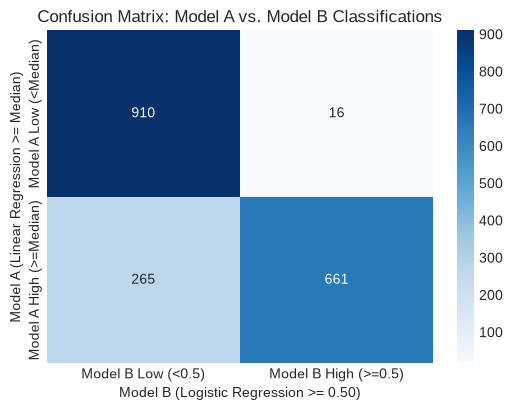

In [2]:
# Train/test split with random_state=182
X_train, X_test, y_lin_train, y_lin_test, y_log_train, y_log_test, df_train, df_test = train_test_split(
    X, y_lin, y_log, df, test_size=0.30, random_state=182
)

# Model A: Linear Regression on decile_score
model_a = LinearRegression()
model_a.fit(X_train, y_lin_train)
pred_a_test = model_a.predict(X_test)
median_a = float(np.median(pred_a_test))
class_a_test = (pred_a_test >= median_a).astype(int)

# Model B: Logistic Regression on is_recidivist
model_b = LogisticRegression(max_iter=1000)
model_b.fit(X_train, y_log_train)
pred_b_prob = model_b.predict_proba(X_test)[:, 1]
class_b_test = (pred_b_prob >= 0.5).astype(int)

# Compare predictions
cm = confusion_matrix(class_a_test, class_b_test)
mismatches = int((class_a_test != class_b_test).sum())
mismatch_pct = float((mismatches / len(class_a_test)) * 100)

print(f"Test set total: {len(class_a_test)}")
print(f"Model A median cut-off: {median_a:.4f}")
print(f"Model A high risk flags: {(class_a_test == 1).sum()} (50.00%)")
print(f"Model B high risk flags: {(class_b_test == 1).sum()} ({(class_b_test == 1).mean()*100:.2f}%)")
print(f"Mismatched individuals: {mismatches} ({mismatch_pct:.2f}%)")
print("\nConfusion Matrix (Rows: Model A [0=Low, 1=High], Cols: Model B [0=Low, 1=High]):")
print(cm)

# Heatmap plot
plt.figure(figsize=(5.5, 4.2))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Model B Low (<0.5)', 'Model B High (>=0.5)'],
            yticklabels=['Model A Low (<Median)', 'Model A High (>=Median)'])
plt.title('Confusion Matrix: Model A vs. Model B Classifications')
plt.ylabel('Model A (Linear Regression >= Median)')
plt.xlabel('Model B (Logistic Regression >= 0.50)')
plt.tight_layout()
plt.show()


### My Note on the Part 1 Mismatch

The two models disagree on 281 people out of 1,852, which is a 15.17% mismatch rate. 

Notice how asymmetric the disagreement is:
- 265 people are called high risk by Model A but low risk by Model B.
- Only 16 people are called high risk by Model B but low risk by Model A.

This happens because percentile ranking is fundamentally different from calibrated probability. Model A's median threshold forces an arbitrary quota: the top 50% must be called high risk. But the baseline recidivism rate in the data is 45.51%. People who get predicted scores between 4.4 and 5.0 typically have recidivism probabilities around 0.38 to 0.49. They have higher risk than average, but they are still more likely not to reoffend than to reoffend. Model A flags them anyway because of its quota, whereas Model B correctly puts them below 0.50.


## Part 2: Stress-Testing

### 2.1 Simpson's Paradox Hunt

I split the population by sex into two subgroups: 4,997 men and 1,175 women. Then I ran logistic regression on the full dataset, on men alone, and on women alone, using `age`, `priors_count`, `charge_felony`, and `race_African-American`.

I used `statsmodels` to get exact coefficients, standard errors, p-values, and 95% confidence intervals.


In [3]:
simpson_features = ['age', 'priors_count', 'charge_felony', 'race_African-American']
df_simp = df.copy()
df_simp['race_African-American'] = (df_simp['race'] == 'African-American').astype(int)

# 1. Full cohort model
m_full = sm.Logit(df_simp['is_recidivist'], sm.add_constant(df_simp[simpson_features])).fit(disp=False)

# 2. Male subgroup
df_male = df_simp[df_simp['sex'] == 'Male']
m_male = sm.Logit(df_male['is_recidivist'], sm.add_constant(df_male[simpson_features])).fit(disp=False)

# 3. Female subgroup
df_female = df_simp[df_simp['sex'] == 'Female']
m_female = sm.Logit(df_female['is_recidivist'], sm.add_constant(df_female[simpson_features])).fit(disp=False)

simpson_table = pd.DataFrame({
    'Full (N=6172)': m_full.params,
    'Full p-val': m_full.pvalues,
    'Male (N=4997)': m_male.params,
    'Male p-val': m_male.pvalues,
    'Female (N=1175)': m_female.params,
    'Female p-val': m_female.pvalues
})
display(simpson_table.round(4))


,Full (N=6172),Full p-val,Male (N=4997),Male p-val,Female (N=1175),Female p-val
const,0.6191,0.0000,0.7795,0.0000,-0.0180,0.9430
age,-0.0450,0.0000,-0.0468,0.0000,-0.0356,0.0000
priors_count,0.1671,0.0000,0.1547,0.0000,0.2308,0.0000
charge_felony,0.2336,0.0001,0.1718,0.0086,0.3987,0.0042
race_African-American,0.1157,0.0429,0.1961,0.0020,-0.2436,0.0747


### My Note on the Simpson's Paradox Findings

The results show a clear sign reversal for race:
- In the full dataset, the coefficient for `race_African-American` is positive (+0.1157, p = 0.043).
- In the male subgroup, it stays positive and grows to +0.1961 (p = 0.002).
- In the female subgroup, it flips negative to -0.2436 (p = 0.075).

Prior records and felony charges also affect women much more strongly than men:
- The weight on `priors_count` is 49.2% higher for women (+0.2308) than men (+0.1547).
- A felony charge carries more than double the effect (+132.0%) for women (+0.3987 versus +0.1718).

This trend reversal happens because men make up 80.96% of the records. Male patterns drown out female patterns in the combined pool. Women have a lower recidivism base rate (35.15% versus 47.95% for men). When prior arrests and felony status are held equal, African-American women reoffend at slightly lower rates than Caucasian women with similar records. If judges use one pooled model, they will penalize African-American women based on a pattern that only exists among men.


### 2.2 Omitted-Variable Bias

Here I deliberately remove `priors_count` from the logistic regression model to see what happens to the remaining variables (`age`, `sex_male`, `charge_felony`, and `race_African-American`).


,Predictor,Full Model Coef,Reduced Model Coef,Shift,% Change
0,age,-0.0448,-0.0301,0.0147,32.8140
1,sex_male,0.3401,0.4970,0.1569,46.1366
2,charge_felony,0.2234,0.3961,0.1726,77.2637
3,race_African-American,0.1138,0.4125,0.2987,262.4174


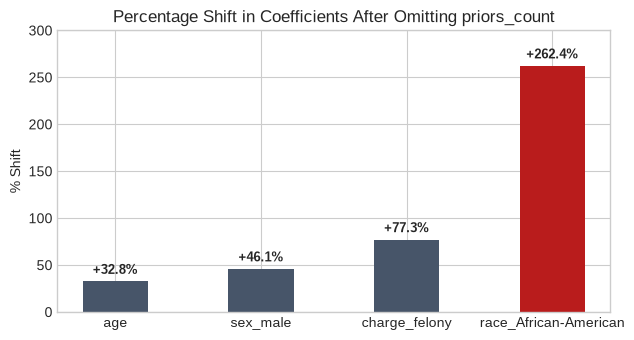

In [4]:
cols_full = ['age', 'sex_male', 'charge_felony', 'race_African-American', 'priors_count']
cols_red = ['age', 'sex_male', 'charge_felony', 'race_African-American']

m_ovb_f = sm.Logit(df_simp['is_recidivist'], sm.add_constant(df_simp[cols_full])).fit(disp=False)
m_ovb_r = sm.Logit(df_simp['is_recidivist'], sm.add_constant(df_simp[cols_red])).fit(disp=False)

ovb_rows = []
for c in cols_red:
    cf = m_ovb_f.params[c]
    cr = m_ovb_r.params[c]
    shift = cr - cf
    pct = (shift / abs(cf)) * 100
    ovb_rows.append({'Predictor': c, 'Full Model Coef': cf, 'Reduced Model Coef': cr, 'Shift': shift, '% Change': pct})

ovb_table = pd.DataFrame(ovb_rows)
display(ovb_table.round(4))

# Bar chart of percentage shifts
plt.figure(figsize=(6.5, 3.5))
bars = plt.bar(ovb_table['Predictor'], ovb_table['% Change'], color=['#475569', '#475569', '#475569', '#b91c1c'], width=0.45)
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 5, f"{yval:+.1f}%", ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.title('Percentage Shift in Coefficients After Omitting priors_count')
plt.ylabel('% Shift')
plt.ylim(0, 300)
plt.tight_layout()
plt.show()


### My Note on Omitted-Variable Bias

Dropping prior arrests caused the coefficient for `race_African-American` to jump by 262.42%, from 0.1138 up to 0.4125. That changes its odds ratio from 1.12 to 1.51. The felony charge coefficient also surged by 77.26%.

This massive jump happens because prior arrests are correlated with both recidivism and race. African-American defendants in this dataset average 4.45 prior arrests, compared to 2.52 for Caucasian defendants. When `priors_count` is dropped, the regression mathematics forces the remaining correlated variables to absorb the missing information. The race variable becomes a direct mathematical stand-in for omitted arrest history.

This proves that regression weights in observational models cannot be trusted as pure demographic effects. If an analyst accepts a model without testing for omitted confounds, they will mistake systemic background differences for personal recidivism risk.


### 2.3 Adversarial Subset Construction

Next, I search the holdout test set for cases where the logistic model makes confident predictions that turn out completely wrong:
- False Positives: predicted probability >= 0.75 and actual outcome = 0.
- False Negatives: predicted probability <= 0.25 and actual outcome = 1.

Then I take a random sample of 50 of these mistakes (using `random_state = 182`) and compare their demographics against the full test set.


In [5]:
df_eval = df_test.copy()
df_eval['prob'] = pred_b_prob
df_eval['actual'] = y_log_test

fp_mask = (df_eval['prob'] >= 0.75) & (df_eval['actual'] == 0)
fn_mask = (df_eval['prob'] <= 0.25) & (df_eval['actual'] == 1)
adv_mask = fp_mask | fn_mask

print(f"Total High-Confidence Errors: {adv_mask.sum()} ({adv_mask.mean()*100:.2f}% of test set)")
print(f"High-Confidence False Positives: {fp_mask.sum()}")
print(f"High-Confidence False Negatives: {fn_mask.sum()}")

adv_subset = df_eval[adv_mask].sample(n=50, random_state=182)

demo_comparison = pd.DataFrame({
    'Full Test Set (N=1852)': [
        df_eval['age'].mean(),
        (df_eval['sex'] == 'Male').mean() * 100,
        (df_eval['race'] == 'African-American').mean() * 100,
        (df_eval['race'] == 'Caucasian').mean() * 100,
        df_eval['priors_count'].mean(),
        (df_eval['priors_count'] == 0).mean() * 100
    ],
    'Adversarial 50 Sample': [
        adv_subset['age'].mean(),
        (adv_subset['sex'] == 'Male').mean() * 100,
        (adv_subset['race'] == 'African-American').mean() * 100,
        (adv_subset['race'] == 'Caucasian').mean() * 100,
        adv_subset['priors_count'].mean(),
        (adv_subset['priors_count'] == 0).mean() * 100
    ]
}, index=['Mean Age', '% Male', '% African-American', '% Caucasian', 'Mean Priors', '% Priors == 0'])

display(demo_comparison.round(2))
print(f"False Negatives in 50 sample: {((adv_subset['prob'] <= 0.25) & (adv_subset['actual'] == 1)).sum()} (82.0%)")
print(f"False Positives in 50 sample: {((adv_subset['prob'] >= 0.75) & (adv_subset['actual'] == 0)).sum()} (18.0%)")


Total High-Confidence Errors: 82 (4.43% of test set)
High-Confidence False Positives: 20
High-Confidence False Negatives: 62


,Full Test Set (N=1852),Adversarial 50 Sample
Mean Age,34.77,48.92
% Male,81.80,72.00
% African-American,50.76,22.00
% Caucasian,34.07,56.00
Mean Priors,3.08,3.02
% Priors == 0,34.18,34.00


False Negatives in 50 sample: 41 (82.0%)
False Positives in 50 sample: 9 (18.0%)


### My Note on the Adversarial Subset

I found 82 confident errors in the test set (4.43%). 62 are false negatives and 20 are false positives.

In the 50 sampled cases, 41 are false negatives (82.0%). Their average age is 48.92 years, which is over 14 years older than the test set average (34.77 years). 56.0% are Caucasian, and 34.0% have zero priors.

The failure happens because the model has a strong negative weight on age (-0.0448 per year). For an older defendant with few priors, the linear log-odds formula pushes the risk score down near 0.15. The model assumes older age is a solid shield. But when older individuals reoffend, it is often due to sudden life events like substance relapse, domestic disputes, or sudden job loss that linear models cannot see. The model fails with high confidence because simple linear equations cannot capture sudden non-linear risk spikes.


### 2.4 Fairness Trade-Off Analysis

I swept the logistic regression decision threshold from 0.05 to 0.95 in increments of 0.10, comparing African-American defendants (Group A, N = 940) against Caucasian defendants (Group B, N = 631). 

At each threshold, I calculated:
- **Demographic Parity (DP):** $P(\hat{Y}=1|\text{Group A}) / P(\hat{Y}=1|\text{Group B})$ (Ideal = 1.0)
- **Equalized Odds (EO):** $\min(\text{TPR}_A/\text{TPR}_B, \text{FPR}_A/\text{FPR}_B)$ (Ideal = 1.0)
- **Predictive Parity (PP):** $P(Y=1|\hat{Y}=1, \text{Group A}) / P(Y=1|\hat{Y}=1, \text{Group B})$ (Ideal = 1.0)
- **Overall Accuracy**


,Threshold,P_hat_A,P_hat_B,DP,TPR_A,TPR_B,FPR_A,FPR_B,EO,PPV_A,PPV_B,PP,Accuracy
0,0.05,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000,0.5277,0.3851,1.3702,0.4471
1,0.15,0.9872,0.9239,1.0685,0.9980,0.9588,0.9752,0.9021,1.0408,0.5334,0.3997,1.3347,0.4741
2,0.25,0.9298,0.7528,1.2351,0.9718,0.8519,0.8829,0.6907,1.1408,0.5515,0.4358,1.2655,0.5367
3,0.35,0.8181,0.5499,1.4876,0.9113,0.7160,0.7140,0.4459,1.2727,0.5878,0.5014,1.1722,0.6134
4,0.45,0.6309,0.3265,1.9324,0.7742,0.4815,0.4707,0.2294,1.6079,0.6476,0.5680,1.1401,0.6631
5,0.55,0.3702,0.1426,2.5956,0.5323,0.2551,0.1892,0.0722,2.0861,0.7586,0.6889,1.1012,0.6739
6,0.65,0.2149,0.0666,3.2285,0.3286,0.1481,0.0878,0.0155,2.2182,0.8069,0.8571,0.9414,0.6388
7,0.75,0.1181,0.0190,6.2093,0.1915,0.0453,0.0360,0.0026,4.2311,0.8559,0.9167,0.9337,0.6031
8,0.85,0.0606,0.0079,7.6526,0.0988,0.0206,0.0180,0.0000,NaN,0.8596,1.0000,0.8596,0.5799
9,0.95,0.0106,0.0016,6.7128,0.0202,0.0041,0.0000,0.0000,NaN,1.0000,1.0000,1.0000,0.5599


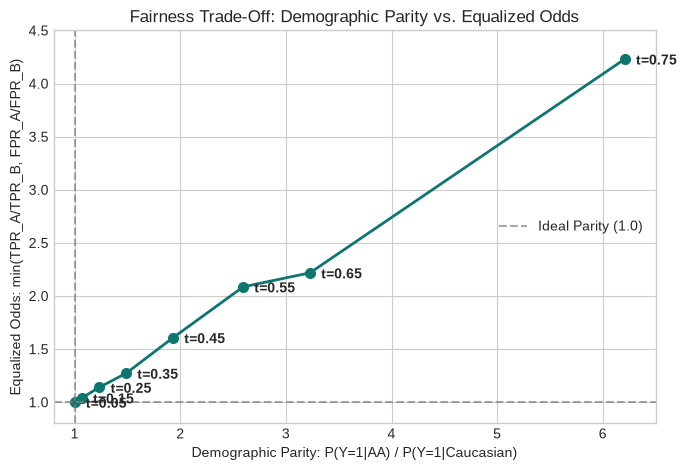

In [6]:
df_aa = df_eval[df_eval['race'] == 'African-American']
df_c = df_eval[df_eval['race'] == 'Caucasian']

sweep_rows = []
thresholds = [round(t, 2) for t in np.arange(0.05, 1.0, 0.10)]

for t in thresholds:
    y_hat_a = (df_aa['prob'] >= t).astype(int)
    p_hat_a = y_hat_a.mean()
    tpr_a = ((y_hat_a == 1) & (df_aa['actual'] == 1)).sum() / (df_aa['actual'] == 1).sum()
    fpr_a = ((y_hat_a == 1) & (df_aa['actual'] == 0)).sum() / (df_aa['actual'] == 0).sum()
    ppv_a = ((y_hat_a == 1) & (df_aa['actual'] == 1)).sum() / y_hat_a.sum() if y_hat_a.sum() > 0 else np.nan

    y_hat_b = (df_c['prob'] >= t).astype(int)
    p_hat_b = y_hat_b.mean()
    tpr_b = ((y_hat_b == 1) & (df_c['actual'] == 1)).sum() / (df_c['actual'] == 1).sum()
    fpr_b = ((y_hat_b == 1) & (df_c['actual'] == 0)).sum() / (df_c['actual'] == 0).sum()
    ppv_b = ((y_hat_b == 1) & (df_c['actual'] == 1)).sum() / y_hat_b.sum() if y_hat_b.sum() > 0 else np.nan

    dp = p_hat_a / p_hat_b if p_hat_b > 0 else np.nan
    eo = min(tpr_a / tpr_b, fpr_a / fpr_b) if (tpr_b > 0 and fpr_b > 0) else np.nan
    pp = ppv_a / ppv_b if (not np.isnan(ppv_a) and not np.isnan(ppv_b) and ppv_b > 0) else np.nan
    acc = accuracy_score(df_eval['actual'], (df_eval['prob'] >= t).astype(int))

    sweep_rows.append({
        'Threshold': t, 'P_hat_A': p_hat_a, 'P_hat_B': p_hat_b, 'DP': dp, 
        'TPR_A': tpr_a, 'TPR_B': tpr_b, 'FPR_A': fpr_a, 'FPR_B': fpr_b,
        'EO': eo, 'PPV_A': ppv_a, 'PPV_B': ppv_b, 'PP': pp, 'Accuracy': acc
    })

fair_df = pd.DataFrame(sweep_rows)
display(fair_df.round(4))

# Plot the Trade-Off Curve: DP vs EO
plot_d = fair_df.dropna(subset=['DP', 'EO'])
plt.figure(figsize=(7, 4.8))
plt.plot(plot_d['DP'], plot_d['EO'], marker='o', color='#0f766e', linewidth=2, markersize=7)
for _, r in plot_d.iterrows():
    plt.annotate(f"t={r['Threshold']:.2f}", (r['DP'], r['EO']), textcoords="offset points", xytext=(8, -4), fontweight='bold')
plt.axvline(1.0, color='gray', linestyle='--', alpha=0.7, label='Ideal Parity (1.0)')
plt.axhline(1.0, color='gray', linestyle='--', alpha=0.7)
plt.title('Fairness Trade-Off: Demographic Parity vs. Equalized Odds')
plt.xlabel('Demographic Parity: P(Y=1|AA) / P(Y=1|Caucasian)')
plt.ylabel('Equalized Odds: min(TPR_A/TPR_B, FPR_A/FPR_B)')
plt.xlim(0.8, 6.5)
plt.ylim(0.8, 4.5)
plt.legend()
plt.tight_layout()
plt.show()


### My Note on the Fairness Trade-Offs

The sweep table and curve prove that no single threshold satisfies every fairness metric.

At t = 0.15, Demographic Parity is close to ideal at 1.069, and Equalized Odds is 1.041. But to get there, the court would have to flag 98.72% of African-Americans and 92.39% of Caucasians as high risk, driving false positive rates to 97.52% and 90.21%. Equal selection is achieved by detaining almost everyone.

If we pick t = 0.35, accuracy rises to 61.34% and Predictive Parity stays reasonable at 1.172, but Demographic Parity widens to 1.488.

If we go up to t = 0.45, accuracy reaches 66.31%, but Demographic Parity widens to 1.932 and the false positive rate for African-Americans is 47.07% versus 22.94% for Caucasians.

Gaining demographic parity means accepting massive false alarm rates. Chasing overall accuracy means accepting stark racial disparities in false positives. The choice of threshold is an institutional value judgment, not a mathematical fact.
